##Install required libraries

In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn

##Import libraries and load datasets

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Load datasets
train = pd.read_csv("dataset_B_training.csv")
test = pd.read_csv("dataset_B_testing.csv")

print("Training dataset:", train.shape)
print("Testing dataset:", test.shape)

Training dataset: (4756, 31)
Testing dataset: (4749, 30)


##Data preprocessing

In [ ]:
# Remove respondent ID from model features
X = train.drop(
    columns=["h1n1_vaccine", "respondent_id"]
)

y = train["h1n1_vaccine"]

# Prepare testing features
X_test = test.drop(columns=["respondent_id"])

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Numerical features: 19
Categorical features: 10
Preprocessing pipeline created successfully.


##Split the training dataset

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape)
print("Validation records:", X_val.shape)

Training records: (3804, 29)
Validation records: (952, 29)


##Build three machine-learning models

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():

    # Create complete pipeline
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Make predictions
    predictions = pipeline.predict(X_val)
    probabilities = pipeline.predict_proba(X_val)[:, 1]

    # Evaluate performance
    accuracy = accuracy_score(y_val, predictions)
    precision = precision_score(y_val, predictions)
    recall = recall_score(y_val, predictions)
    f1 = f1_score(y_val, predictions)
    auc = roc_auc_score(y_val, probabilities)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": auc
    })

    trained_models[name] = pipeline

    print("\nModel:", name)
    print(classification_report(y_val, predictions))

# Display model comparison
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print(results_df.round(4))


Model: Logistic Regression
              precision    recall  f1-score   support

           0       0.81      0.76      0.78       577
           1       0.66      0.72      0.69       375

    accuracy                           0.74       952
   macro avg       0.73      0.74      0.73       952
weighted avg       0.75      0.74      0.74       952


Model: Decision Tree
              precision    recall  f1-score   support

           0       0.79      0.72      0.75       577
           1       0.62      0.70      0.66       375

    accuracy                           0.71       952
   macro avg       0.70      0.71      0.70       952
weighted avg       0.72      0.71      0.71       952


Model: Random Forest
              precision    recall  f1-score   support

           0       0.78      0.82      0.80       577
           1       0.70      0.65      0.67       375

    accuracy                           0.75       952
   macro avg       0.74      0.73      0.74       952
we

##Visualise model performance

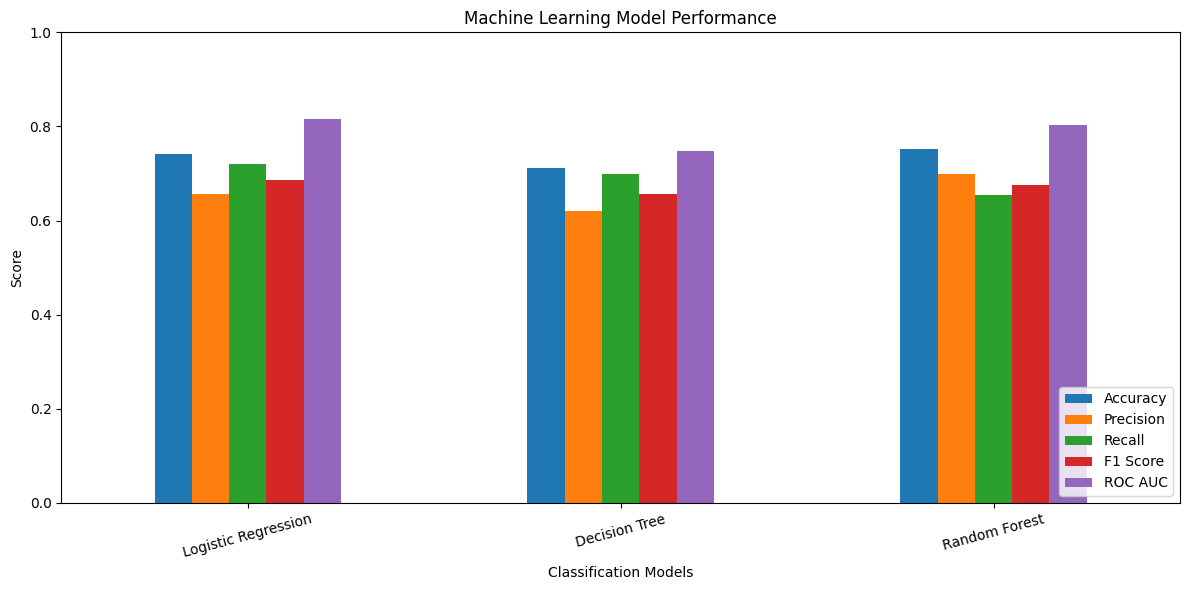

In [ ]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance")
plt.ylabel("Score")
plt.xlabel("Classification Models")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

##Confusion matrix

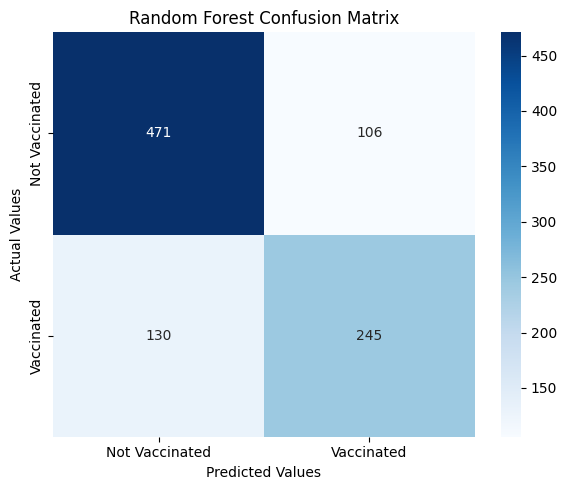

In [ ]:
# Select Random Forest
best_model = trained_models["Random Forest"]

# Predict validation data
y_pred = best_model.predict(X_val)

# Create confusion matrix
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Vaccinated", "Vaccinated"],
    yticklabels=["Not Vaccinated", "Vaccinated"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.tight_layout()
plt.show()

##Identify the most important features

                                     Feature  Importance
9                      num__doctor_recc_h1n1    0.154309
14                    num__opinion_h1n1_risk    0.128990
13          num__opinion_h1n1_vacc_effective    0.105065
0                          num__h1n1_concern    0.032769
15          num__opinion_h1n1_sick_from_vacc    0.032108
1                        num__h1n1_knowledge    0.027621
11                        num__health_worker    0.027043
18        num__number_chronic_med_conditions    0.024282
16                     num__household_adults    0.023352
17                   num__household_children    0.021177
6           num__behavioral_large_gatherings    0.013281
7               num__behavioral_outside_home    0.013145
8                 num__behavioral_touch_face    0.013144
44  cat__census_msa_MSA, Not Principle  City    0.012851
26           cat__education_College Graduate    0.012727


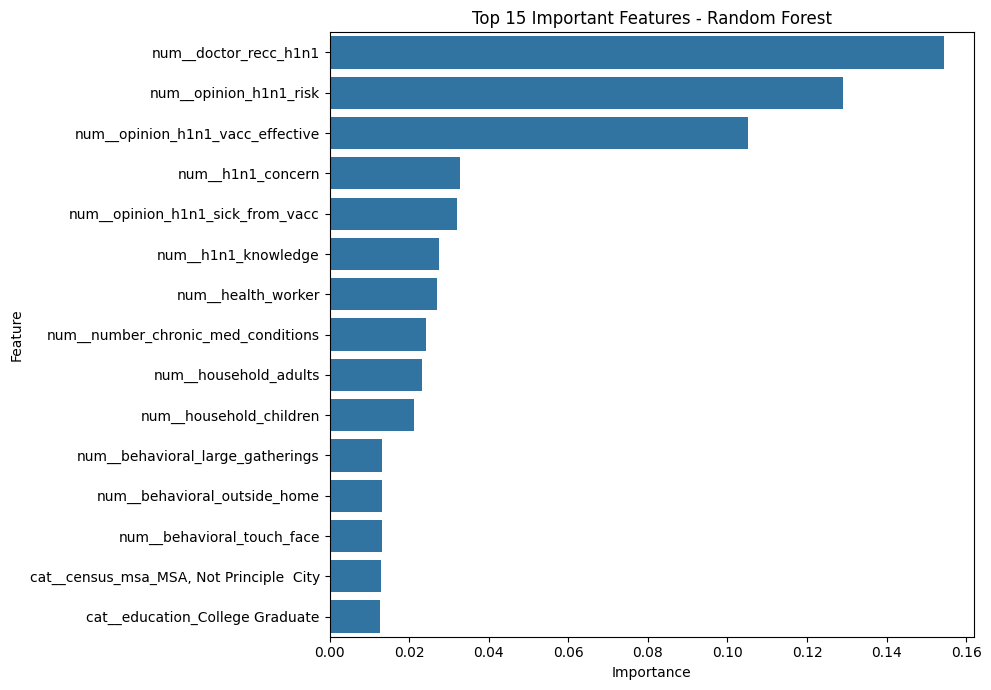

In [ ]:
# Get trained Random Forest model
rf_model = trained_models["Random Forest"]

# Get feature names after preprocessing
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance
importance = rf_model.named_steps[
    "classifier"
].feature_importances_

# Create feature importance dataframe
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Display top 15 features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

# Plot top 15 features
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Random Forest")
plt.tight_layout()
plt.show()

##Train the final model and predict testing data

In [ ]:
# Select best model based on F1 score
best_model_name = results_df.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]["Model"]

print("Selected model:", best_model_name)

# Train selected model using all labelled training data
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", models[best_model_name])
])

final_model.fit(X, y)

# Predict testing dataset
test_predictions = final_model.predict(X_test)

test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Create prediction file
submission = pd.DataFrame({
    "respondent_id": test["respondent_id"],
    "h1n1_vaccine_prediction": test_predictions,
    "vaccination_probability": test_probabilities
})

# Save results
submission.to_csv(
    "H1N1_Final_Predictions.csv",
    index=False
)

print(submission.head())

print("Final predictions saved successfully!")

Selected model: Logistic Regression
   respondent_id  h1n1_vaccine_prediction  vaccination_probability
0           4757                        0                 0.274113
1           4758                        0                 0.095408
2           4759                        0                 0.124541
3           4760                        0                 0.265653
4           4761                        0                 0.140200
Final predictions saved successfully!


In [ ]:

# Generate final predictions

# Train the selected model using all training records
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", models[best_model_name])
])

final_model.fit(X, y)

# Predict the testing dataset
predictions = final_model.predict(X_test)

# Create submission dataframe
submission = pd.DataFrame({
    "respondent_id": test["respondent_id"],
    "h1n1_vaccine": predictions
})

# Save submission file
submission.to_csv(
    "submission.csv",
    index=False
)

# Display submission results
print(submission.head(10))

print("\nTotal predictions:", len(submission))
print("\nPrediction distribution:")
print(submission["h1n1_vaccine"].value_counts())

print("\nSubmission file created successfully!")


   respondent_id  h1n1_vaccine
0           4757             0
1           4758             0
2           4759             0
3           4760             0
4           4761             0
5           4762             1
6           4763             1
7           4764             1
8           4765             1
9           4766             0

Total predictions: 4749

Prediction distribution:
h1n1_vaccine
0    2724
1    2025
Name: count, dtype: int64

Submission file created successfully!


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd
import joblib

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

# Train and evaluate
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_val)
    y_prob = pipeline.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1 Score": f1_score(y_val, y_pred),
        "ROC AUC": roc_auc_score(y_val, y_prob)
    })

    trained_models[name] = pipeline

# Model comparison
results_df = pd.DataFrame(results)

print(results_df.round(4))

# Save comparison
results_df.to_csv("Model_Results.csv", index=False)


                 Model  Accuracy  Precision  Recall  F1 Score  ROC AUC
0  Logistic Regression    0.7416     0.6569  0.7200    0.6870   0.8163
1        Decision Tree    0.7122     0.6194  0.6987    0.6566   0.7473
2        Random Forest    0.7521     0.6980  0.6533    0.6749   0.8033


In [ ]:
import joblib
import os

os.makedirs("submitted_models", exist_ok=True)

for name, model in trained_models.items():

    filename = name.replace(" ", "_") + ".pkl"

    joblib.dump(
        model,
        "submitted_models/" + filename
    )

    print(name, "saved successfully")

Logistic Regression saved successfully
Decision Tree saved successfully
Random Forest saved successfully


In [ ]:
# Load Logistic Regression
loaded_model = joblib.load(
    "submitted_models/Logistic_Regression.pkl"
)

# Predict validation data
predictions = loaded_model.predict(X_val)

print("Loaded model predictions:")
print(predictions[:10])

Loaded model predictions:
[0 1 0 0 0 0 0 0 1 0]


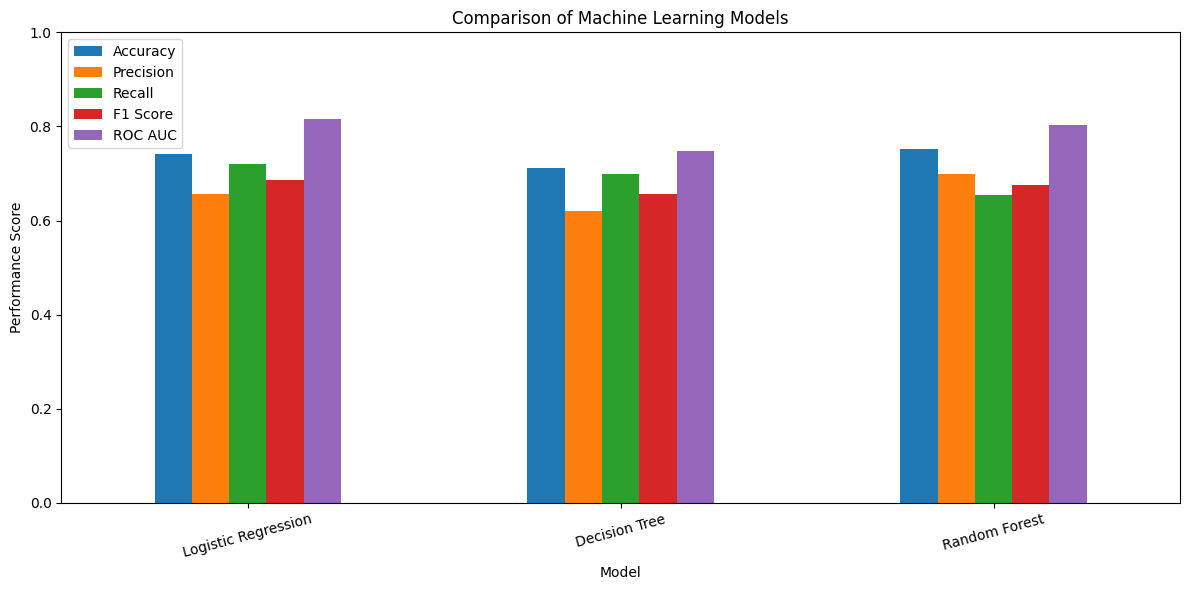

In [ ]:
import matplotlib.pyplot as plt

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("Model_Comparison.png", dpi=300)
plt.show()

In [ ]:

from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Decision Tree pipeline
dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

# Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Decision Tree parameters
dt_params = {
    "classifier__max_depth": [5, 8, 10, 15, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

# Random Forest parameters
rf_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [8, 12, 16, None],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

# Tune Decision Tree
dt_grid = GridSearchCV(
    dt_pipeline,
    dt_params,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best Decision Tree Parameters:")
print(dt_grid.best_params_)
print("Best F1 Score:", dt_grid.best_score_)

# Tune Random Forest
rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("\nBest Random Forest Parameters:")
print(rf_grid.best_params_)
print("Best F1 Score:", rf_grid.best_score_)


Best Decision Tree Parameters:
{'classifier__max_depth': 8, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10}
Best F1 Score: 0.678110739222503

Best Random Forest Parameters:
{'classifier__max_depth': 8, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}
Best F1 Score: 0.7052042548262125


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

optimized_models = {
    "Optimized Decision Tree": dt_grid.best_estimator_,
    "Optimized Random Forest": rf_grid.best_estimator_
}

optimized_results = []

for name, model in optimized_models.items():

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    optimized_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1 Score": f1_score(y_val, predictions),
        "ROC AUC": roc_auc_score(y_val, probabilities)
    })

optimized_df = pd.DataFrame(optimized_results)

print(optimized_df.round(4))

optimized_df.to_csv(
    "Optimized_Model_Results.csv",
    index=False
)


                     Model  Accuracy  Precision  Recall  F1 Score  ROC AUC
0  Optimized Decision Tree    0.7111     0.6168  0.7040    0.6575   0.7590
1  Optimized Random Forest    0.7426     0.6702  0.6827    0.6764   0.7992


                     Model  Accuracy  Precision  Recall  F1 Score  ROC AUC
0      Logistic Regression    0.7416     0.6569  0.7200    0.6870   0.8163
1            Decision Tree    0.7122     0.6194  0.6987    0.6566   0.7473
2            Random Forest    0.7521     0.6980  0.6533    0.6749   0.8033
3  Optimized Decision Tree    0.7111     0.6168  0.7040    0.6575   0.7590
4  Optimized Random Forest    0.7426     0.6702  0.6827    0.6764   0.7992


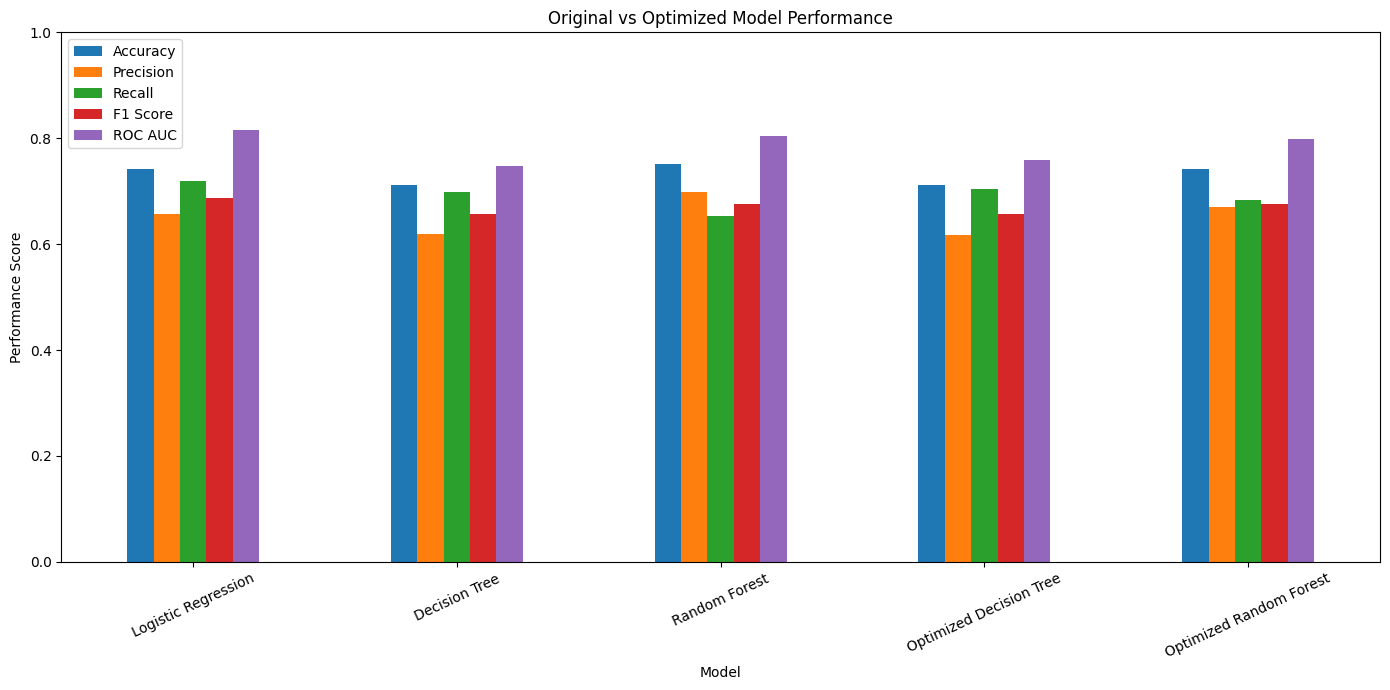

In [ ]:

# Combine previous and optimised results
all_results = pd.concat(
    [results_df, optimized_df],
    ignore_index=True
)

print(all_results.round(4))

# Save complete comparison
all_results.to_csv(
    "Complete_Model_Comparison.csv",
    index=False
)

# Visual comparison
all_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
].plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Original vs Optimized Model Performance")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("Complete_Model_Comparison.png", dpi=300)
plt.show()


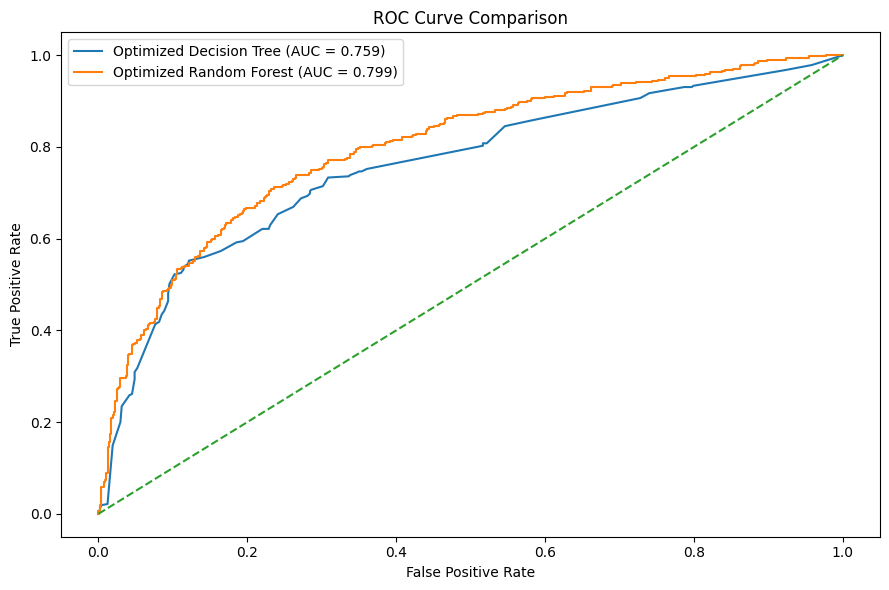

In [ ]:

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 6))

for name, model in optimized_models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_val,
        probabilities
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.tight_layout()
plt.savefig("ROC_Curve.png", dpi=300)
plt.show()


In [ ]:

import joblib
import os

os.makedirs("Final_Models", exist_ok=True)

# Save optimised models
joblib.dump(
    dt_grid.best_estimator_,
    "Final_Models/Optimized_Decision_Tree.pkl"
)

joblib.dump(
    rf_grid.best_estimator_,
    "Final_Models/Optimized_Random_Forest.pkl"
)

print("Optimised models saved successfully!")


Optimised models saved successfully!
